# MNIST Digit Generation with GANs: Experiments

*Building, training, and evaluating a Generative Adversarial Network (GAN) to generate handwritten digits.*

In [1]:
%pip install numpy pandas matplotlib torch torchvision torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 46.4 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 21.7 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 50.2 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 16.4 MB/s  0:00:18m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 20.1 MB/s  0:00:16m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 41.6 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 39.0 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 MB 33.8 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 43.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 MB 14.2 MB/s  0:00:20m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 40.1 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Notebook Overview

This notebook trains a GAN to generate handwritten digits and compares five truncation settings across three random seeds. It examines the resulting images and measures precision and recall. **In JupyterLab, use the Table of Contents panel in the left sidebar to jump to any heading.**

## Hypothesis

We expect that decreasing the truncation parameter may improve image quality but reduce diversity, whereas increasing it may increase diversity at the expense of image quality

### Why Do We Expect This?

- **Decreasing truncation:** Reduces the range of random inputs given to the generator. We expect this to produce more similar digits, reducing diversity. It may improve image quality by limiting variation, but this is not guaranteed

- **Increasing truncation:** Expands the range of random inputs, allowing the generator to produce more varied digits. However, greater variation may also produce blurry, distorted or unrealistic images

We expect a trade-off between image quality and diversity, but the experiment will determine whether this trade-off actually occurs

We will compare five truncation values (0.25, 0.5, 1, 1.5 and 2) across three random seeds while keeping other training parameters fixed in the main experiment

## General Overview

We use the **MNIST dataset**, which contains images of handwritten digits. Our goal is to generate new digits with different handwriting styles.

First, we use a **GAN**, which consists of two neural networks working together:
- **Generator:** Creates new handwritten digits from random noise.
- **Discriminator:** Tries to distinguish generated digits from real ones.

Next, we use a **separate CNN** to evaluate the generated digits. It helps us measure how realistic the digits are (**precision**) and how much variety they have (**recall**).

Finally, we **visualise the results** to see the generated digits, examine their quality and variety, and understand how well the models performed.

## Effects of Random Seeds

The random seed affects the initial model weights, random noise, training data order and dropout. These differences can influence how the GAN learns and the quality of its generated images

We use three random seeds (42, 123 and 456) to check whether the baseline produces consistent results despite these random differences

## Evaluation Methods: Precision, Recall and Visual Analysis

We use three methods to evaluate how changing truncation affects the quality and diversity of generated MNIST digits

- **Precision (Image Quality):** Measures how closely the generated images resemble real handwritten digits using features extracted by a trained CNN. Higher precision suggests that more generated images have realistic characteristics

- **Recall (Image Diversity):** Measures how much of the variety found in real MNIST digits is represented by the generated images. Higher recall suggests that the generator produces a wider range of digit shapes and writing styles

- **Visual Analysis:** Involves examining generated images to assess their clarity, recognisability and variety. It helps us identify blurry digits, repeated patterns and possible mode collapse that numerical scores might not fully explain

### Why Do We Use These Methods?

Our experiment investigates how truncation affects both image quality and diversity. Precision and recall provide numerical measurements that allow us to compare different truncation values and random seeds.

Visual analysis complements these measurements by showing what the generated images actually look like. Together, these methods help us understand the trade-off between image quality and diversity and draw more reliable conclusions.


## Table of Contents

- [Notebook Overview](#notebook-overview)
- [Hypothesis](#hypothesis)
- [General Overview](#general-overview)
- [Effects of Random Seeds](#effects-of-random-seeds)
- [Evaluation Methods: Precision, Recall and Visual Analysis](#evaluation-methods-precision-recall-and-visual-analysis)
- [Why Do We Use These Methods?](#why-do-we-use-these-methods)
    
### 1. Setup and Configuration
- [1.1 Import Libraries](#11-import-libraries)
- [1.2 Choose Whether to Train or Reuse Results](#12-choose-whether-to-train-or-reuse-results)
- [1.3 Choose Where to Save Results](#13-choose-where-to-save-results)
- [1.4 Set the Truncation Experiment](#14-set-the-truncation-experiment)
- [1.5 Set Training and Model Parameters](#15-set-training-and-model-parameters)

### 2. Prepare the MNIST Dataset
- [2.1 Load the Dataset](#21-load-the-dataset)
- [2.2 Preview a Training Image](#22-preview-a-training-image)

### 3. Build the GAN
- [3.1 Define the Generator](#31-define-the-generator)
- [3.2 Define the Discriminator](#32-define-the-discriminator)
- [3.3 Create Models for Inspection](#33-create-models-for-inspection)
- [3.4 Inspect the Generator Layers](#34-inspect-the-generator-layers)
- [3.5 Inspect the Discriminator Layers](#35-inspect-the-discriminator-layers)

### 4. Set Up Loss Functions and Optimisers
- [4.1 Define the Loss Functions](#41-define-the-loss-functions)
- [4.2 Create the Optimisers](#42-create-the-optimisers)

### 5. Train or Load the GAN
- [5.1 Save Training Results](#51-save-training-results)
- [5.2 Define the Training Steps](#52-define-the-training-steps)
- [5.3 Train the GAN for One Seed](#53-train-the-gan-for-one-seed)
- [5.4 Run or Reuse the Experiments](#54-run-or-reuse-the-experiments)

### 6. Evaluate Image Quality and Diversity
- [6.1 Define an MNIST Classifier](#61-define-an-mnist-classifier)
- [6.2 Train the Classifier](#62-train-the-classifier)
- [6.3 Define Feature-Based Precision and Recall](#63-define-feature-based-precision-and-recall)
- [6.4 Evaluate the Baseline GAN](#64-evaluate-the-baseline-gan)
- [6.5 Compare All Truncation Values and Seeds](#65-compare-all-truncation-values-and-seeds)

### 7. Visualise the Results
- [7.1 Plot Training Losses](#71-plot-training-losses)
- [7.2 View Training Progress](#72-view-training-progress)
- [7.3 Compare Final Generated Digits](#73-compare-final-generated-digits)

### 8. Discussion and Conclusions
- [8.1 Compare Image Quality and Diversity](#81-compare-image-quality-and-diversity)
- [8.2 Compare Results Across the Three Seeds](#82-compare-results-across-the-three-seeds)
- [8.3 Explain Mode Collapse](#83-explain-mode-collapse)
- [8.4 Justify the Parameter Choices](#84-justify-the-parameter-choices)
  - [Hyperparameters and Nuisance Hyperparameters](#hyperparameters-and-nuisance-hyperparameters)
- [8.5 How Parameter Changes Could Affect the Results](#85-how-parameter-changes-could-affect-the-results)
- [8.6 Sensitivity Check Findings](#sensitivity-check-findings)
- [8.7 Final Conclusion](#87-final-conclusion)

## 1. Setup and Configuration

### 1.1 Import Libraries

We import the libraries used throughout the notebook. PyTorch builds and trains the neural networks, while NumPy works with arrays and random numbers. Matplotlib displays images and graphs, pandas creates tables, and `Path` handles file locations

In [1759]:
import numpy as np
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

### 1.2 Choose Whether to Train or Reuse Results

Set `QUICK = True` to use results that were saved earlier instead of training again. Set it to `False` to train new models for all three random seeds. When `QUICK` is `True`, a later cell checks that the saved files exist

In [1761]:
# Change QUICK to True to run load the cache results
# Instead of training it from the beginning
QUICK = True

Set `SENSITIVITY_CHECK = True` to test a different learning rate and save the results in separate folders without overwriting the original experiments. Set it to False to use the original learning rate and experiment folders. When True, the sensitivity experiments are performed using the same three random seeds

In [1763]:
# Sensitivity check: Test a different learning rate
SENSITIVITY_CHECK = True

### 1.3 Choose Where to Save Results

This cell chooses the main folder for saved experiment files. Each truncation setting will have its own subfolder inside `results`. Keeping results in separate folders prevents experiments from getting mixed up

In [1765]:
RESULTS_DIR = Path("results")

### 1.4 Set the Truncation Experiment

We will test five truncation values: 0.25, 0.5, 1, 1.5 and 2. `CURRENT_TRUNCATION` selects a position in the list, so index `2` chooses the baseline value `1`. The code also chooses a folder for the selected experiment

In [1767]:
# Main experiment: Test different truncation values and analyze their effects on GAN performance

POSSIBLE_TRUNCATION_VALUES = [0.25, 0.5, 1, 1.5, 2]
CURRENT_TRUNCATION = 2  # Index of the selected truncation value

TRUNCATION_FOLDERS = {
    0.25: "experiment1",
    0.5: "experiment2",
    1: "baseline",
    1.5: "experiment3",
    2: "experiment4"
}

TRUNCATION = POSSIBLE_TRUNCATION_VALUES[CURRENT_TRUNCATION]  # Default/Baseline value: 1 (index 2, no truncation)

# Select and create the experiment folder
EXPERIMENT_DIR = RESULTS_DIR / TRUNCATION_FOLDERS[TRUNCATION]
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

if SENSITIVITY_CHECK:
    LEARNING_RATE = 0.0002
    EXPERIMENT_DIR = (
        RESULTS_DIR / "sensitivity_lr_0002"
        / TRUNCATION_FOLDERS[TRUNCATION]
    )
else:
    LEARNING_RATE = 0.002
    EXPERIMENT_DIR = RESULTS_DIR / TRUNCATION_FOLDERS[TRUNCATION]

# Create the experiment folder
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

### 1.5 Set Training and Model Parameters

This cell collects the settings used to build and train the GAN. For example, `BATCH_SIZE` determines how many images are processed together, while `NUM_EPOCHS` controls how many times training goes through the dataset. We keep these settings fixed when comparing different truncation values

In [1769]:
# 1. Dataset
num_workers = 0
BATCH_SIZE = 64

# 2. Define the Model Architecture (generator and discriminator)

# Generator
LATENT_DIM = 100
GEN_HIDDEN_DIMS = [32, 64, 128]
GEN_LEAKY_SLOPE = 0.2
GEN_DROPOUT = 0.3
GEN_OUTPUT_DIM = 784

# Discriminator
DISC_INPUT_DIM = 784
DISC_HIDDEN_DIMS = [128, 64, 32]
DISC_LEAKY_SLOPE = 0.2
DISC_DROPOUT = 0.3
DISC_OUTPUT_DIM = 1

# Create the generator and discriminator
RANDOM_SEEDS = [42, 123, 456] 

# 3. Configure the Loss Functions and Optimizers

# 3.1 Loss function hyperparameters
LABEL_SMOOTHING = False

# Real loss function
SMOOTH_REAL_LABEL = 0.9

# Fake loss function
# (no variables)

# 3.2 Optimizers
OPTIMIZERS_LEARNING_RATE = LEARNING_RATE

# 4. Train the Model

Z_SIZE = 100
NUM_EPOCHS = 100
PRINT_EVERY = 400 
SAMPLE_SIZE = 16

## 2. Prepare the MNIST Dataset

### 2.1 Load the Dataset

MNIST contains pictures of handwritten digits from 0 to 9. This cell downloads the dataset and converts the images into PyTorch tensors with values between 0 and 1. Data loaders then provide the images in small batches

In [1772]:
from torchvision import datasets
import torchvision.transforms as transforms

transform = transforms.ToTensor()

# load the training and testing data
train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, num_workers=num_workers, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=BATCH_SIZE, num_workers=num_workers)

### 2.2 Preview a Training Image

This cell takes a batch of MNIST training images and displays one digit. It removes the axes so the digit is easier to see. This is a quick way to check that the dataset loaded correctly

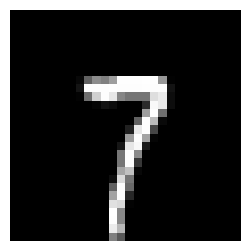

In [1774]:
# Verify the dataset has loaded correctly

# Show a single image

dataiter = iter(train_loader)
images, labels = next(dataiter)
images = images.numpy()
img = np.squeeze(images[3])

fig = plt.figure(figsize=(3,3))
ax = fig.add_subplot(111)

ax.imshow(img, cmap='gray')
ax.axis('off')
plt.show()

## 3. Build the GAN

### 3.1 Define the Generator

The generator turns 100 random input numbers into a new handwritten-digit image. Its layers gradually change those numbers into 784 pixel values, which make up a 28 × 28 image. The final `Tanh` layer keeps the output between -1 and 1

In [1777]:
# Define the generator

def create_generator():
    generator = nn.Sequential(
        nn.Linear(LATENT_DIM, GEN_HIDDEN_DIMS[0]), # 100 -> 32 
        nn.LeakyReLU(GEN_LEAKY_SLOPE),             # Activation function
        nn.Dropout(GEN_DROPOUT),                   # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[0], GEN_HIDDEN_DIMS[1]), # 32 -> 64
        nn.LeakyReLU(GEN_LEAKY_SLOPE),                     # Activation function
        nn.Dropout(GEN_DROPOUT),                           # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[1], GEN_HIDDEN_DIMS[2]), # 64 -> 128
        nn.LeakyReLU(GEN_LEAKY_SLOPE),                     # Activation function
        nn.Dropout(GEN_DROPOUT),                           # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[2], GEN_OUTPUT_DIM),     # 128 -> 784
        nn.Tanh()                                          # Scale output to [-1, 1]
    )

    return generator

### 3.2 Define the Discriminator

The discriminator examines an image and produces one score about whether it looks real or generated. It first turns the 28 × 28 image into a list of 784 numbers. The remaining layers use those numbers to produce the score

In [1779]:
# Define the discriminator

def create_discriminator():
    discriminator = nn.Sequential(
        nn.Flatten(), # Flatten 28x28 images into 784 features

        nn.Linear(DISC_INPUT_DIM, DISC_HIDDEN_DIMS[0]), # 784 -> 128
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                 # Activation function
        nn.Dropout(DISC_DROPOUT),                       # Prevent overfitting

        nn.Linear(DISC_HIDDEN_DIMS[0], DISC_HIDDEN_DIMS[1]), # 128 -> 64
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                      # Activation function 
        nn.Dropout(DISC_DROPOUT),                            # Prevent overfitting

        nn.Linear(DISC_HIDDEN_DIMS[1], DISC_HIDDEN_DIMS[2]), # 64 -> 32 
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                      # Activation function
        nn.Dropout(DISC_DROPOUT),                            # Prevent overfitting 

        nn.Linear(DISC_HIDDEN_DIMS[2], DISC_OUTPUT_DIM)      # 32 -> 1 (real/fake logit)
    )

    return discriminator

### 3.3 Create Models for Inspection

This cell creates temporary versions of the generator and discriminator so we can inspect them. The random seed makes their initial settings repeatable. These temporary models are not the ones trained in the main experiments

In [1781]:
# Import torchinfo for pretty print of the layers of
# the generator and discriminator
from torchinfo import summary

CURRENT_SEED = 0

torch.manual_seed(RANDOM_SEEDS[CURRENT_SEED])
np.random.seed(RANDOM_SEEDS[CURRENT_SEED])

# instantiate generator 
G_view = create_generator()

# instantiate discriminator
D_view = create_discriminator()

### 3.4 Inspect the Generator Layers

This cell displays a layer-by-layer summary of the generator. The summary shows how the size of the data changes through the network. It helps us check the architecture before training starts

In [1783]:
# Display the layers of the generator
# print(G)

# Generator
print('Generator')
summary(G_view, input_size=(BATCH_SIZE, LATENT_DIM))

Generator


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [64, 784]                 --
├─Linear: 1-1                            [64, 32]                  3,232
├─LeakyReLU: 1-2                         [64, 32]                  --
├─Dropout: 1-3                           [64, 32]                  --
├─Linear: 1-4                            [64, 64]                  2,112
├─LeakyReLU: 1-5                         [64, 64]                  --
├─Dropout: 1-6                           [64, 64]                  --
├─Linear: 1-7                            [64, 128]                 8,320
├─LeakyReLU: 1-8                         [64, 128]                 --
├─Dropout: 1-9                           [64, 128]                 --
├─Linear: 1-10                           [64, 784]                 101,136
├─Tanh: 1-11                             [64, 784]                 --
Total params: 114,800
Trainable params: 114,800
Non-trainable params: 0

### 3.5 Inspect the Discriminator Layers

This cell displays a layer-by-layer summary of the discriminator. It shows how the network processes a 28 × 28 image. This check does not train or change the discriminator

In [1785]:
# Display the layers of the discriminator
# print(D)

# Discriminator
print('Discriminator')
summary(D_view, input_size=(BATCH_SIZE, 1, 28, 28))

Discriminator


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [64, 1]                   --
├─Flatten: 1-1                           [64, 784]                 --
├─Linear: 1-2                            [64, 128]                 100,480
├─LeakyReLU: 1-3                         [64, 128]                 --
├─Dropout: 1-4                           [64, 128]                 --
├─Linear: 1-5                            [64, 64]                  8,256
├─LeakyReLU: 1-6                         [64, 64]                  --
├─Dropout: 1-7                           [64, 64]                  --
├─Linear: 1-8                            [64, 32]                  2,080
├─LeakyReLU: 1-9                         [64, 32]                  --
├─Dropout: 1-10                          [64, 32]                  --
├─Linear: 1-11                           [64, 1]                   33
Total params: 110,849
Trainable params: 110,849
Non-trainable params: 0
To

## 4. Set Up Loss Functions and Optimisers

### 4.1 Define the Loss Functions

A loss function measures how different a prediction is from its target. Here, real images have a target of 1 (or 0.9 when label smoothing is enabled), and fake images have a target of 0. These functions help calculate the errors used during GAN training

In [1788]:
# The loss functions that help the discriminator distinguish 
# real from fake images

# distinguish real images
def real_loss(D_out, smooth=False):
    batch_size = D_out.size(0)

    # label smoothing
    if smooth:
        labels = torch.ones(batch_size) * SMOOTH_REAL_LABEL
    else:
        labels = torch.ones(batch_size)

    criterion = nn.BCEWithLogitsLoss()
    
    loss = criterion(D_out.squeeze(-1), labels)

    return loss

# distinguish fake images
def fake_loss(D_out):
    batch_size = D_out.size(0)
    labels = torch.zeros(batch_size)
    
    criterion = nn.BCEWithLogitsLoss()

    loss = criterion(D_out.squeeze(-1), labels)
    
    return loss

### 4.2 Create the Optimisers

An optimiser updates a model's weights so it can learn from its errors. This cell creates one Adam optimiser for the generator and another for the discriminator. Both use the learning rate chosen in the settings

In [1790]:
import torch.optim as optim

def create_optimizers(G, D):
    # Create optimizers for the generator and discriminator
    g_optimizer = optim.Adam(G.parameters(), lr=OPTIMIZERS_LEARNING_RATE)
    d_optimizer = optim.Adam(D.parameters(), lr=OPTIMIZERS_LEARNING_RATE)

    return g_optimizer, d_optimizer

## 5. Train or Load the GAN

### 5.1 Save Training Results

This function saves the results of one training run to a file. It stores the generator and discriminator weights, training losses, generated sample images, and important settings. We can use the saved file later without running that training again

In [1793]:
# Save the results for one random seed
def save_results(seed, G, D, losses, samples):

    torch.save({
        "seed": seed,
        "generator": G.state_dict(),
        "discriminator": D.state_dict(),
        "losses": losses,
        "samples": samples,
        "config": {
            "epochs": NUM_EPOCHS,
            "batch_size": BATCH_SIZE,
            "latent_dim": Z_SIZE,
            "truncation": TRUNCATION,
            "learning_rate": OPTIMIZERS_LEARNING_RATE,
            "label_smoothing": LABEL_SMOOTHING,
            "gen_hidden_dims": GEN_HIDDEN_DIMS,
            "disc_hidden_dims": DISC_HIDDEN_DIMS
        }
    }, EXPERIMENT_DIR / f"seed_{seed}.pt")

### 5.2 Define the Training Steps

These functions describe the two parts of a GAN training step. First, the discriminator learns to tell real images from generated ones; then, the generator learns to produce images that look real to the discriminator. Random input numbers are sampled from a range set by `TRUNCATION`

In [1795]:
def train_discriminator(real_images, G, D, d_optimizer):
    batch_size = real_images.size(0)

    d_optimizer.zero_grad()

    # Train with real images
    D_real = D(real_images)
    d_real_loss = real_loss(D_real, smooth=LABEL_SMOOTHING)

    # Train with fake images
    # z = np.random.uniform(-1, 1, size=(batch_size, z_size))
    z = np.random.uniform(-TRUNCATION, TRUNCATION, size=(batch_size, Z_SIZE)) # Apply truncation
    z = torch.from_numpy(z).float()
    fake_images = G(z)

    D_fake = D(fake_images.detach())
    d_fake_loss = fake_loss(D_fake)

    # Update discriminator
    d_loss = d_real_loss + d_fake_loss
    d_loss.backward()
    d_optimizer.step()

    return d_loss


def train_generator(real_images, G, D, g_optimizer):
    batch_size = real_images.size(0)

    g_optimizer.zero_grad()

    # Generate fake images
    # z = np.random.uniform(-1, 1, size=(batch_size, z_size))
    z = np.random.uniform(-TRUNCATION, TRUNCATION, size=(batch_size, Z_SIZE)) # Apply truncation
    z = torch.from_numpy(z).float()
    fake_images = G(z)

    # Train with flipped labels
    D_fake = D(fake_images)
    g_loss = real_loss(D_fake)

    # Update generator
    g_loss.backward()
    g_optimizer.step()

    return g_loss

### 5.3 Train the GAN for One Seed

This function trains a fresh generator and discriminator using one random seed. It repeatedly updates both networks and records their losses after each epoch. It also saves sample digits made from fixed random inputs, so we can see how the images change during training

In [1797]:
RESULTS_DIR.mkdir(exist_ok=True)


# Train the GAN for one random seed
def train_one_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Instantiate generator and discriminator
    G = create_generator()
    D = create_discriminator()

    # Create fresh optimizers
    g_optimizer, d_optimizer = create_optimizers(G, D)

    # Store generated images and training losses
    samples = []
    losses = []

    # Fixed random noise
    fixed_z = np.random.uniform(-1, 1, size=(SAMPLE_SIZE, Z_SIZE))
    fixed_z = torch.from_numpy(fixed_z).float()

    G.train()
    D.train()

    for epoch in range(NUM_EPOCHS):
        for batch_i, (real_images, _) in enumerate(train_loader):
            batch_size = real_images.size(0)

            # Rescale images from [0, 1] to [-1, 1]
            real_images = real_images * 2 - 1

            # Train discriminator
            d_loss = train_discriminator(
                real_images, G, D, d_optimizer
            )

            # Train generator
            g_loss = train_generator(
                real_images, G, D, g_optimizer
            )

            if batch_i % PRINT_EVERY == 0:
                print(
                    f"Seed {seed} | Epoch [{epoch+1}/{NUM_EPOCHS}] "
                    f"| d_loss: {d_loss.item():.4f} "
                    f"| g_loss: {g_loss.item():.4f}"
                )

        # Store losses after each epoch
        losses.append((d_loss.item(), g_loss.item()))

        # Generate and save sample images
        G.eval()

        with torch.no_grad():
            samples_z = G(fixed_z * TRUNCATION)
            samples.append(samples_z.cpu())

        G.train()

    return G, D, losses, samples

### 5.4 Run or Reuse the Experiments

This cell decides whether to train the GAN or reuse saved results. If `QUICK` is `True`, it checks that the required files exist for all five truncation values and three random seeds. Otherwise, it trains and saves a separate model for each combination of truncation value and seed.

In [1800]:

# Run or reuse all experiments

selected_truncation = TRUNCATION
selected_dir = EXPERIMENT_DIR

for truncation, folder in TRUNCATION_FOLDERS.items():
    TRUNCATION = truncation

    if SENSITIVITY_CHECK:
        EXPERIMENT_DIR = RESULTS_DIR / "sensitivity_lr_0002" / folder
    else:
        EXPERIMENT_DIR = RESULTS_DIR / folder

    EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

    for seed in RANDOM_SEEDS:
        checkpoint_path = EXPERIMENT_DIR / f"seed_{seed}.pt"

        print(
            f"Experiment: {folder} | Truncation: {truncation} "
            f"| LR: {LEARNING_RATE} | Seed: {seed}"
        )

        if QUICK:
            if not checkpoint_path.is_file():
                raise FileNotFoundError(
                    f"Missing checkpoint: {checkpoint_path}"
                )
        else:
            G, D, losses, samples = train_one_seed(seed)
            save_results(seed, G, D, losses, samples)

            del G, D, losses, samples

# Restore the selected experiment
TRUNCATION = selected_truncation
EXPERIMENT_DIR = selected_dir

print("All 15 experiments are ready")

Experiment: experiment1 | Truncation: 0.25 | LR: 0.0002 | Seed: 42
Experiment: experiment1 | Truncation: 0.25 | LR: 0.0002 | Seed: 123
Experiment: experiment1 | Truncation: 0.25 | LR: 0.0002 | Seed: 456
Experiment: experiment2 | Truncation: 0.5 | LR: 0.0002 | Seed: 42
Experiment: experiment2 | Truncation: 0.5 | LR: 0.0002 | Seed: 123
Experiment: experiment2 | Truncation: 0.5 | LR: 0.0002 | Seed: 456
Experiment: baseline | Truncation: 1 | LR: 0.0002 | Seed: 42
Experiment: baseline | Truncation: 1 | LR: 0.0002 | Seed: 123
Experiment: baseline | Truncation: 1 | LR: 0.0002 | Seed: 456
Experiment: experiment3 | Truncation: 1.5 | LR: 0.0002 | Seed: 42
Experiment: experiment3 | Truncation: 1.5 | LR: 0.0002 | Seed: 123
Experiment: experiment3 | Truncation: 1.5 | LR: 0.0002 | Seed: 456
Experiment: experiment4 | Truncation: 2 | LR: 0.0002 | Seed: 42
Experiment: experiment4 | Truncation: 2 | LR: 0.0002 | Seed: 123
Experiment: experiment4 | Truncation: 2 | LR: 0.0002 | Seed: 456
All 15 experiments

This cell decides whether to train the GAN or reuse saved results for **one selected truncation value**. If `QUICK` is `True`, it checks that the required checkpoints exist for all three random seeds. Otherwise, it trains and saves a separate model for each seed at the selected truncation value.

In [1802]:
# # Train and save the GAN for each random seed
# if QUICK:
#     print("Loading saved results")
    
#     for seed in RANDOM_SEEDS:
#         checkpoint_path = EXPERIMENT_DIR / f"seed_{seed}.pt"

#         if not checkpoint_path.is_file():
#             raise FileNotFoundError(
#                 f"Missing checkpoint: {checkpoint_path}"
#             )

#     print("All 3 checkpoints found. Ready for evaluation.")
# else:
#     for seed in RANDOM_SEEDS:
#         G, D, losses, samples = train_one_seed(seed)
#         save_results(seed, G, D, losses, samples)

## 6. Evaluate Image Quality and Diversity

### 6.1 Define an MNIST Classifier

This cell defines a convolutional neural network (CNN) that learns to recognise handwritten digits. Its first layers find useful patterns in the images, and its final layer predicts the digit. We will also use the learned patterns to compare real and generated images

In [1805]:
import torch
import torch.nn as nn

# CNN for extracting meaningful features from MNIST images
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU()
        )

        self.output = nn.Linear(128, 10)

    def forward(self, x):
        features = self.features(x)
        logits = self.output(features)

        return logits, features


### 6.2 Train the Classifier

This cell trains the CNN on real MNIST images and their correct digit labels. It repeats the training for five epochs and prints the average loss each time. Afterwards, it switches the CNN to evaluation mode

In [1807]:
# Initialize the CNN
torch.manual_seed(777)

classifier = MNISTClassifier()

# Path for saving and loading the classifier
CLASSIFIER_PATH = RESULTS_DIR / "mnist_classifier.pt"

if CLASSIFIER_PATH.is_file():
    # Load the previously trained classifier
    classifier.load_state_dict(
        torch.load(
            CLASSIFIER_PATH,
            map_location="cpu",
            weights_only=True
        )
    )

    print("Loaded saved MNIST classifier.")

elif QUICK:
    raise FileNotFoundError(
        f"Classifier checkpoint not found: {CLASSIFIER_PATH}"
    )

else:
    # Configure classifier training
    optimizer = torch.optim.Adam(
        classifier.parameters(), lr=0.001
    )

    criterion = nn.CrossEntropyLoss()

    NUM_CLASSIFIER_EPOCHS = 5

    # Train the classifier
    for epoch in range(NUM_CLASSIFIER_EPOCHS):
        classifier.train()
        total_loss = 0

        for images, labels in train_loader:
            optimizer.zero_grad()

            # Classify real MNIST digits
            logits, _ = classifier(images)

            # Calculate loss
            loss = criterion(logits, labels)

            # Update model weights
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch [{epoch + 1}/{NUM_CLASSIFIER_EPOCHS}] "
            f"| Loss: {total_loss / len(train_loader):.4f}"
        )

    # Save the trained classifier
    CLASSIFIER_PATH.parent.mkdir(parents=True, exist_ok=True)
    torch.save(classifier.state_dict(), CLASSIFIER_PATH)

    print("MNIST classifier saved.")

# Prepare the classifier for evaluation
classifier.eval()

Loaded saved MNIST classifier.


MNISTClassifier(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=1568, out_features=128, bias=True)
    (8): ReLU()
  )
  (output): Linear(in_features=128, out_features=10, bias=True)
)

### 6.3 Define Feature-Based Precision and Recall

These helper functions turn real and generated images into lists of learned features. They compare nearby features to measure precision (how closely generated images resemble real ones) and recall (how much of the real images' variety is represented). This provides a numerical comparison alongside the visual results

In [1809]:
import torch
import pandas as pd

# Use the trained CNN to extract image features
feature_extractor = classifier.features
feature_extractor.eval()


# Extract features from real MNIST images
def extract_real_features(feature_extractor, test_loader, num_samples=4000):
    feature_extractor.eval()
    device = next(feature_extractor.parameters()).device

    features = []

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)

            batch_features = feature_extractor(images)
            features.append(batch_features.cpu())

            if sum(len(f) for f in features) >= num_samples:
                break

    return torch.cat(features, dim=0)[:num_samples]


# Extract features from generated MNIST images
def extract_fake_features(
    G, feature_extractor, truncation,
    num_samples=2000, batch_size=128
):
    G.eval()
    feature_extractor.eval()

    device = next(G.parameters()).device
    feature_device = next(feature_extractor.parameters()).device

    rng = torch.Generator().manual_seed(999)
    features = []

    with torch.no_grad():
        for i in range(0, num_samples, batch_size):
            n = min(batch_size, num_samples - i)

            # Generate latent noise
            z = torch.rand(n, Z_SIZE, generator=rng) * 2 - 1
            z = z.to(device) * truncation

            # Generate images
            fake_images = G(z)

            # Reshape and rescale to [0, 1]
            fake_images = fake_images.reshape(-1, 1, 28, 28)
            fake_images = (fake_images + 1) / 2

            # Extract learned features
            batch_features = feature_extractor(
                fake_images.to(feature_device)
            )

            features.append(batch_features.cpu())

    return torch.cat(features, dim=0)


# Calculate distance to kth nearest neighbour
def calculate_radii(features, k=5, batch_size=256):
    features = features.cpu().float()

    if len(features) <= k:
        raise ValueError("Not enough samples for k neighbours.")

    radii = []

    for i in range(0, len(features), batch_size):
        end = min(i + batch_size, len(features))

        distances = torch.cdist(
            features[i:end], features
        )

        # Exclude each image from its own neighbours
        row_indices = torch.arange(end - i)
        col_indices = torch.arange(i, end)
        distances[row_indices, col_indices] = float("inf")

        kth_distance = distances.topk(
            k, largest=False
        ).values[:, -1]

        radii.append(kth_distance)

    return torch.cat(radii)


# Measure how many query samples fall within reference neighbourhoods
def calculate_coverage(
    queries, references, radii, batch_size=256
):
    queries = queries.cpu().float()
    references = references.cpu().float()

    covered = 0

    for i in range(0, len(queries), batch_size):
        distances = torch.cdist(
            queries[i:i + batch_size], references
        )

        matches = (
            distances <= radii.unsqueeze(0)
        ).any(dim=1)

        covered += matches.sum().item()

    return covered / len(queries)


# Calculate generative precision and recall
def calculate_precision_recall(
    real_features, fake_features, k=5
):
    real_radii = calculate_radii(real_features, k)
    fake_radii = calculate_radii(fake_features, k)

    # Precision: generated images near real images
    precision = calculate_coverage(
        fake_features, real_features, real_radii
    )

    # Recall: real images covered by generated images
    recall = calculate_coverage(
        real_features, fake_features, fake_radii
    )

    return precision, recall

### 6.4 Evaluate the Baseline GAN

First, this cell compares two groups of real MNIST images to establish a reference. Next, it loads the baseline generator (truncation 1, seed 42) and compares its images with real images. Both comparisons report precision and recall

In [1811]:
# Evaluate the baseline GAN using Precision and Recall
NUM_SAMPLES = 2000

# Extract real MNIST features
all_real_features = extract_real_features(
    feature_extractor, test_loader,
    num_samples=NUM_SAMPLES * 2
)

# Split real features into two independent groups
real_1 = all_real_features[:NUM_SAMPLES]
real_2 = all_real_features[NUM_SAMPLES:]

# Load the appropriate baseline GAN
if SENSITIVITY_CHECK:
    checkpoint_path = (
        RESULTS_DIR / "sensitivity_lr_0002" / "baseline"
        / f"seed_{RANDOM_SEEDS[0]}.pt"
    )
else:
    checkpoint_path = (
        RESULTS_DIR / "baseline"
        / f"seed_{RANDOM_SEEDS[0]}.pt"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

G = create_generator()
G.load_state_dict(checkpoint["generator"])
G.eval()

# Extract features from baseline GAN images
fake_features = extract_fake_features(
    G, feature_extractor,
    truncation=1.0,
    num_samples=NUM_SAMPLES
)

# Real vs Real baseline
real_precision, real_recall = calculate_precision_recall(
    real_1, real_2
)

# Real vs Generated GAN
gan_precision, gan_recall = calculate_precision_recall(
    real_1, fake_features
)

print("Real vs Real (Reference)")
print(f"Precision: {real_precision:.4f}")
print(f"Recall: {real_recall:.4f}")

print("\nReal vs Generated (Baseline GAN)")
print(f"Precision: {gan_precision:.4f}")
print(f"Recall: {gan_recall:.4f}")

Real vs Real (Reference)
Precision: 0.9485
Recall: 0.9430

Real vs Generated (Baseline GAN)
Precision: 0.9615
Recall: 0.0505


### 6.5 Compare All Truncation Values and Seeds

This cell evaluates the saved generators for every truncation value and all three random seeds. It calculates precision and recall for each run using the same method. The table at the end shows the average score and standard deviation for each truncation value

In [1813]:
# Evaluate precision and recall across experiments
evaluation_results = []

# Select the experiments and checkpoint directory
if SENSITIVITY_CHECK:
    experiment_folders = TRUNCATION_FOLDERS
    checkpoint_dir = RESULTS_DIR / "sensitivity_lr_0002"
else:
    experiment_folders = TRUNCATION_FOLDERS
    checkpoint_dir = RESULTS_DIR

for truncation, folder in experiment_folders.items():
    for seed in RANDOM_SEEDS:

        # Load trained generator
        checkpoint = torch.load(
            checkpoint_dir / folder / f"seed_{seed}.pt",
            map_location="cpu",
            weights_only=True
        )

        G = create_generator()
        G.load_state_dict(checkpoint["generator"])
        G.eval()

        # Extract generated image features
        fake_features = extract_fake_features(
            G,
            feature_extractor,
            truncation=truncation,
            num_samples=NUM_SAMPLES
        )

        # Calculate precision and recall
        precision, recall = calculate_precision_recall(
            real_1, fake_features
        )

        evaluation_results.append({
            "truncation": truncation,
            "seed": seed,
            "precision": precision,
            "recall": recall
        })

        print(
            f"Truncation: {truncation} | Seed: {seed} "
            f"| Precision: {precision:.4f} "
            f"| Recall: {recall:.4f}"
        )

        del G, fake_features


# Summarise across random seeds
df = pd.DataFrame(evaluation_results)

summary = df.groupby("truncation")[
    ["precision", "recall"]
].agg(["mean", "std"])

display(summary.round(4))


Truncation: 0.25 | Seed: 42 | Precision: 0.7815 | Recall: 0.0005
Truncation: 0.25 | Seed: 123 | Precision: 0.9215 | Recall: 0.0010
Truncation: 0.25 | Seed: 456 | Precision: 0.9285 | Recall: 0.0005
Truncation: 0.5 | Seed: 42 | Precision: 0.9520 | Recall: 0.0230
Truncation: 0.5 | Seed: 123 | Precision: 0.9355 | Recall: 0.0495
Truncation: 0.5 | Seed: 456 | Precision: 0.8700 | Recall: 0.0150
Truncation: 1 | Seed: 42 | Precision: 0.9615 | Recall: 0.0505
Truncation: 1 | Seed: 123 | Precision: 0.9310 | Recall: 0.2170
Truncation: 1 | Seed: 456 | Precision: 0.9355 | Recall: 0.1420
Truncation: 1.5 | Seed: 42 | Precision: 0.9220 | Recall: 0.2720
Truncation: 1.5 | Seed: 123 | Precision: 0.9030 | Recall: 0.2510
Truncation: 1.5 | Seed: 456 | Precision: 0.9250 | Recall: 0.2215
Truncation: 2 | Seed: 42 | Precision: 0.9230 | Recall: 0.2185
Truncation: 2 | Seed: 123 | Precision: 0.9295 | Recall: 0.3220
Truncation: 2 | Seed: 456 | Precision: 0.9275 | Recall: 0.2250


precision          recall        
                mean     std    mean     std
truncation                                  
0.25          0.8772  0.0829  0.0007  0.0003
0.50          0.9192  0.0434  0.0292  0.0181
1.00          0.9427  0.0165  0.1365  0.0834
1.50          0.9167  0.0119  0.2482  0.0254
2.00          0.9267  0.0033  0.2552  0.0580

## 7. Visualise the Results

### 7.1 Plot Training Losses

This cell plots the saved generator and discriminator losses for each seed. The lines show how the losses change over training epochs. They help us compare training behaviour, although the loss curves alone cannot tell us how realistic the digits look

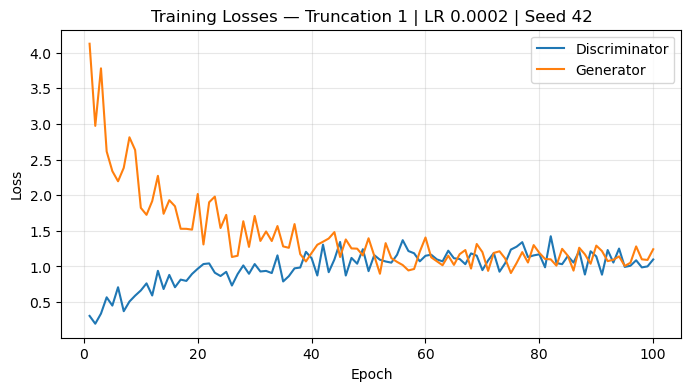

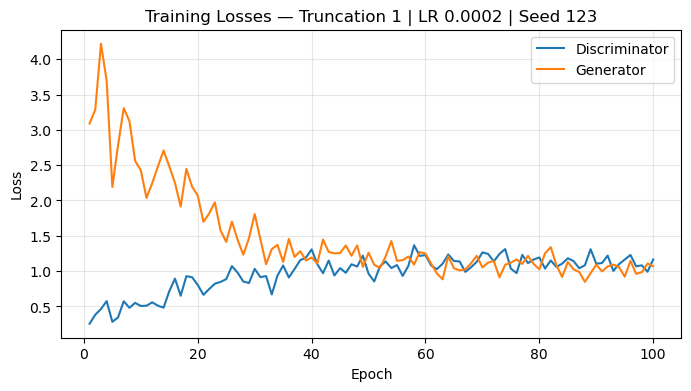

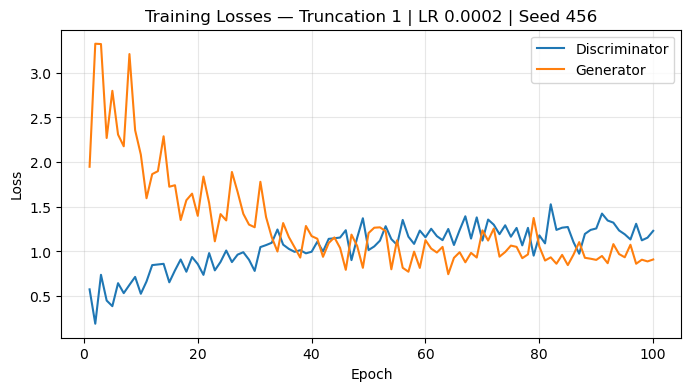

In [1816]:
# Plot training losses for a specific seed

def plot_training_losses(seed):

    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    losses = np.array(checkpoint["losses"])
    epochs = np.arange(1, len(losses) + 1)

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.plot(epochs, losses[:, 0], label="Discriminator")
    ax.plot(epochs, losses[:, 1], label="Generator")

    ax.set_title(
        f"Training Losses — Truncation {TRUNCATION} "
        f"| LR {LEARNING_RATE} | Seed {seed}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.show()

for seed in RANDOM_SEEDS:
    plot_training_losses(seed)

### 7.2 View Training Progress

This cell displays digits saved at different points during training. Each row shows a different training stage, making changes in the generated images easier to notice. It displays the progress separately for each random seed

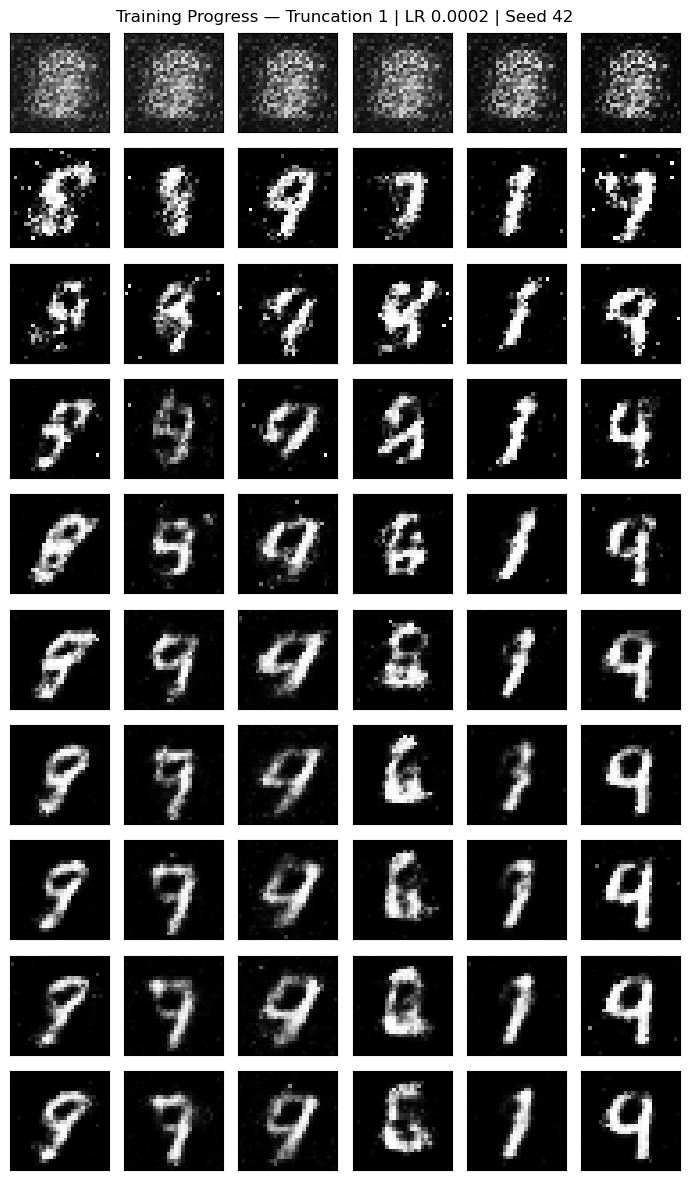

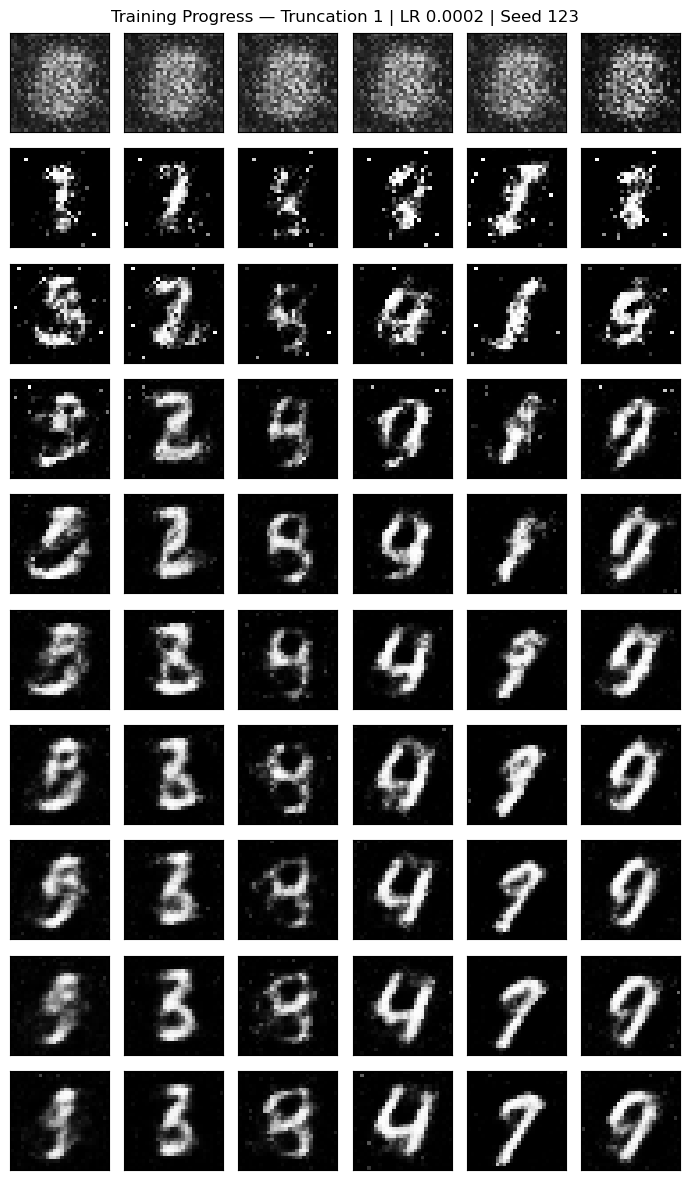

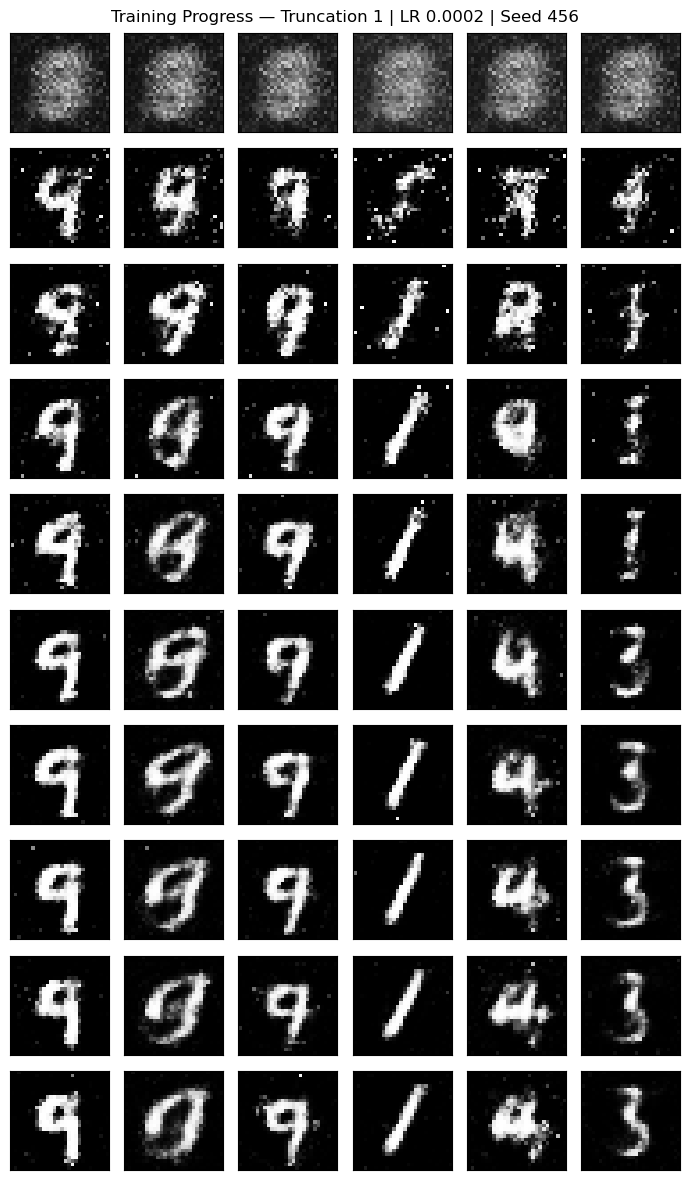

In [1818]:
# Visualize generated images across training epochs

def view_training_progress(seed):
    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    samples = checkpoint["samples"]

    rows = min(10, len(samples))  # Display up to 10 training stages
    cols = min(6, len(samples[0]))

    # Select evenly spaced stages, including the final one
    stages = np.linspace(0, len(samples) - 1, rows, dtype=int)
    image_indices = np.linspace(0, len(samples[0]) - 1, cols, dtype=int)

    fig, axes = plt.subplots(
        figsize=(7, 12),
        nrows=rows,
        ncols=cols,
        sharex=True,
        sharey=True,
        squeeze=False
    )

    for stage, ax_row in zip(stages, axes):
        for img_idx, ax in zip(image_indices, ax_row):
            img = samples[stage][img_idx].detach().cpu().numpy()
            ax.imshow(img.reshape((28, 28)), cmap="Greys_r", vmin=-1, vmax=1)
            ax.xaxis.set_visible(False)
            ax.yaxis.set_visible(False)

    fig.suptitle(
        f"Training Progress — Truncation {TRUNCATION} "
        f"| LR {LEARNING_RATE} | Seed {seed}"
    )

    plt.tight_layout()
    plt.show()


for seed in RANDOM_SEEDS:
    view_training_progress(seed)

### 7.3 Compare Final Generated Digits

This cell shows the final generated digits from the selected experiment. For each random seed, it displays 16 images in a 4 × 4 grid. These grids help us visually compare clarity, repetition, and diversity

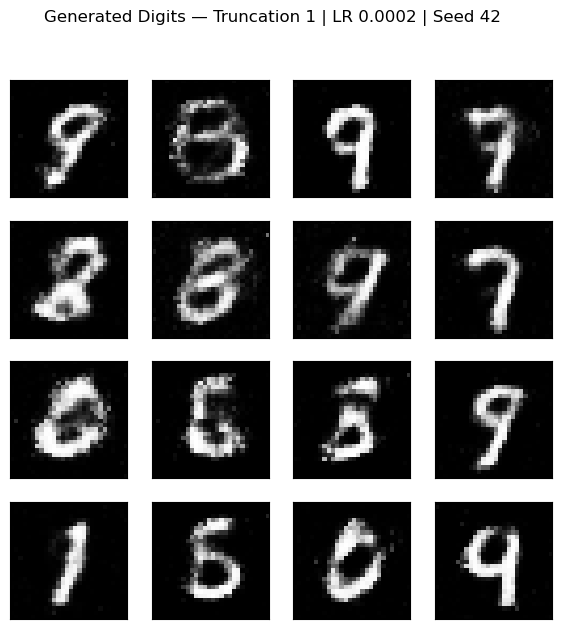

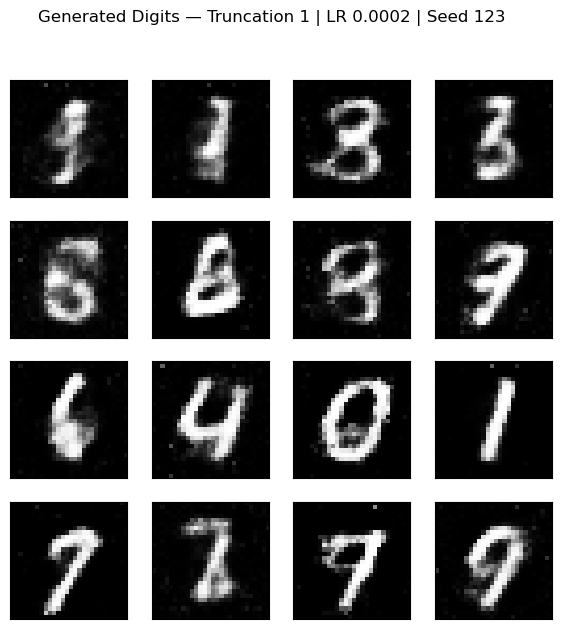

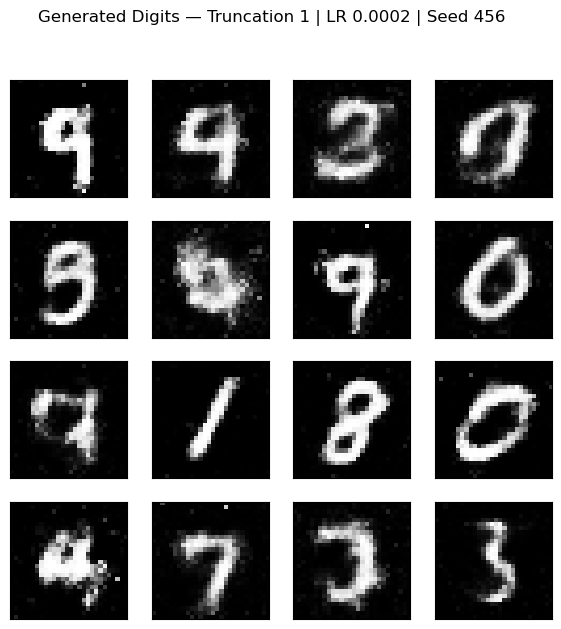

In [1820]:
# View generated images for a specific seed

def view_samples(seed):

    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    samples = checkpoint["samples"]

    fig, axes = plt.subplots(
        figsize=(7, 7),
        nrows=4, ncols=4,
        sharey=True, sharex=True
    )

    for ax, img in zip(axes.flatten(), samples[-1]):
        img = img.detach().cpu().numpy()
        ax.xaxis.set_visible(False)
        ax.yaxis.set_visible(False)
        ax.imshow(img.reshape((28, 28)), cmap="Greys_r")

    fig.suptitle(
        f"Generated Digits — Truncation {TRUNCATION} "
        f"| LR {LEARNING_RATE} | Seed {seed}"
    )
    plt.show()


for seed in RANDOM_SEEDS:
    view_samples(seed)

## 8. Discussion and Conclusions


### 8.1 Compare Image Quality and Diversity

- **0.25:** Seeds 42 and 123 produce different digits, although some are blurry. Seed 456 generates almost identical vertical patterns, unlike the more varied baseline images

- **0.5:** Seed 123 generates different digits, but seeds 42 and 456 repeatedly produce almost identical patterns. This shows considerably less diversity than the baseline

- **1 (Baseline):** All three seeds produce recognisable digits with different shapes and writing styles, although some images are blurry or distorted

- **1.5:** All three seeds produce a variety of recognisable digits, with diversity comparable to or better than the baseline. Some images remain unclear

- **2:** All three seeds generate different digits, showing good diversity compared with the baseline, although some contain noise or distorted features

Overall, truncation values of 1.5 and 2 maintain or improve diversity compared with the baseline. Smaller truncation values do not consistently improve visual quality and sometimes produce almost identical images


### 8.2 Compare Results Across the Three Seeds

| Truncation | Mean Precision | Precision Std | Mean Recall | Recall Std |
|---|---:|---:|---:|---:|
| **0.25** | 0.9538 | 0.0414 | 0.1563 | 0.1358 |
| **0.5** | 0.9755 | 0.0424 | 0.0620 | 0.1074 |
| **1 (Baseline)** | 0.8992 | 0.0145 | 0.1912 | 0.0072 |
| **1.5** | 0.9192 | 0.0020 | 0.2683 | 0.0068 |
| **2** | 0.9205 | 0.0073 | 0.2448 | 0.0145 |

#### Comparison with the Baseline

- **0.25:** Precision increases by 0.0546, but recall decreases by 0.0349. The large standard deviations indicate less consistent performance across seeds

- **0.5:** Precision increases by 0.0763, but recall decreases by 0.1292. Two seeds achieve zero recall, showing a severe loss of diversity compared with the baseline

- **1.5:** Precision increases by 0.0200 and recall increases by 0.0771. Both metrics improve compared with the baseline, with smaller standard deviations

- **2:** Precision increases by 0.0213 and recall increases by 0.0536. Both metrics improve, although recall is slightly lower than at truncation 1.5

Overall, truncation values of 1.5 and 2 outperform the baseline in both precision and recall. Truncation 1.5 achieves the highest average recall and the most consistent results across the three seeds


### 8.3 Explain Mode Collapse

Mode collapse occurs when a generator produces identical or very similar images from different random inputs instead of learning a variety of outputs

In our experiment, seed 456 at truncation 0.25 and seeds 42 and 456 at truncation 0.5 repeatedly produce almost identical patterns. This behaviour is consistent with mode collapse

These runs achieve precision of 1.0 but recall of 0.0, showing that high precision alone does not guarantee good image diversity

Blurry or distorted images do not necessarily indicate mode collapse. The main issue is repeatedly generating the same or very similar outputs


### 8.4 Why Did We Choose These Parameters?

#### i) Experimental Parameters

We selected five truncation values to investigate how changing the range of random noise affects image quality and diversity.

We also used three random seeds to check whether our findings remain consistent across different training runs.

| Parameter | Justification |
|---|---|
| **Truncation: 0.25, 0.5, 1, 1.5, 2** | Compares narrower and wider noise ranges against the baseline of 1 |
| **Seeds: 42, 123, 456** | Measure variability across independent training runs |

#### ii) Nuisance Hyperparameters

Nuisance hyperparameters are settings that affect the results but are not the main focus of our investigation.

We initially kept these settings fixed to make comparisons easier. We later tested different learning rates to investigate whether the same setting was suitable for every truncation value.

| Parameter | Justification |
|---|---|
| **Latent dimension: 100** | Provides enough space for variation without making the model too large |
| **Learning rate: 0.002** | Initial setting used for training. We later compared it with 0.0002 |
| **Batch size: 64** | Balances memory use and gradient stability |
| **Epochs: 100** | Allows sufficient training time within our computational budget |
| **LeakyReLU slope: 0.2** | Allows gradients to flow for negative inputs |
| **Dropout: 0.3** | Helps prevent overfitting through regularisation |
| **No label smoothing** | Keeps the initial training setup simple |

These parameters can influence training stability, image quality and diversity. Therefore, our results may change if different settings are used.


### 8.5 How Could Changing the Parameters Affect Our Results?

#### i) Potential Effects of Other Hyperparameters

Changing other hyperparameters could affect the quality, diversity and stability of the generated images

For example, reducing the learning rate may improve training stability, while increasing the number of epochs may help the generator learn clearer digits

| Parameter change | Possible improvement |
|---|---|
| Reduce the learning rate from **0.002 to 0.0002** | May stabilise training, although more epochs may be needed |
| Increase batch size from **64 to 128** | May reduce gradient noise, but requires more memory |
| Compare latent dimensions of **50, 100 and 200** | Tests whether a larger latent space improves diversity or a smaller one makes learning easier |
| Reduce dropout from **0.3 to 0.1** | May help if excessive regularisation is limiting learning, but could increase overfitting |
| Enable real-label smoothing at **0.9** | May reduce discriminator overconfidence and help the generator learn |
| Increase training from **100 to 150 epochs** | May improve digit clarity if learning is still progressing, but could also allow instability to develop |

These changes could affect our conclusions about which truncation value performs best. A separate sensitivity check is needed to determine whether our findings remain consistent under different settings

Our experiment also changes the noise range during both training and generation, so the results do not isolate the effect of changing truncation only during image generation


#### ii) Learning Rate Tuning

##### Comparison of Learning Rates

To investigate the effect of the learning rate, we compared 0.002 and 0.0002 across all five truncation values, using three random seeds per condition

| Truncation | LR 0.002 (P / R) | LR 0.0002 (P / R) |
|---|---|---|
| 0.25 | 0.9538 / 0.1563 | 0.8772 / 0.0007 |
| 0.5 | 0.9755 / 0.0620 | 0.9192 / 0.0292 |
| 1.0 | 0.8992 / 0.1912 | 0.9427 / 0.1365 |
| 1.5 | 0.9192 / 0.2683 | 0.9167 / 0.2482 |
| 2.0 | 0.9205 / 0.2448 | 0.9267 / 0.2552 |


##### Results and Interpretation

The original learning rate of 0.002 generally achieved higher recall, especially at smaller truncation values. At truncation 0.25, reducing the learning rate caused recall to fall from 0.1563 to almost zero, indicating very limited diversity

At truncation 1, the lower learning rate improved precision but reduced recall. At truncation 1.5, the original learning rate produced slightly better results for both metrics

Truncation 2 was the only condition where the lower learning rate improved both average metrics. However, its recall varied considerably more across random seeds

Overall, the results show that learning rate affects the balance between precision, recall and consistency. The most suitable learning rate therefore depends on the truncation value and the evaluation priorities


#### iii) Learning Rate Selection

We selected the learning rate for each truncation value by comparing precision, recall and consistency across the three random seeds

| Truncation | Selected LR | Justification |
|---|---|---|
| 0.25 | 0.002 | Higher average precision and recall |
| 0.5 | 0.002 | Higher average precision and recall, although diversity remains limited |
| 1.0 | 0.002 | Higher recall, despite lower precision |
| 1.5 | 0.002 | Slightly higher precision and recall, with consistent results |
| 2.0 | 0.0002 | Slightly higher average precision and recall, but greater recall variability |

We prioritised recall because generating diverse digits is an important part of our investigation, while also considering precision and consistency

These selections represent the better-performing choices among the two learning rates tested, rather than necessarily the optimal settings


#### iv) Visual Analysis

Visual inspection of the generated digits at truncations 1 and 1.5 shows recognisable handwritten numbers, although some images remain blurry or distorted

At the lower learning rate, truncation 1.5 appears to generate a greater variety of digit shapes and writing styles than truncation 1. This supports its higher recall and suggests better coverage of the handwritten digit distribution


### 8.6 Sensitivity Check Findings  

Reducing the learning rate from 0.002 to 0.0002 produces different results

- **Recall:** Truncation 1.5 continues to outperform the baseline, suggesting that its improvement in diversity is consistent across both learning rates

- **Precision:** Truncation 1.5 no longer outperforms the baseline, suggesting that its advantage in measured image quality depends on the learning rate

- **Visual Analysis:** Both truncation values generate recognisable handwritten digits, although some images remain blurry or distorted. Truncation 1.5 appears to produce a greater variety of digit shapes and writing styles, supporting the higher recall scores

- **Consistency:** Truncation 1.5 shows less variation in precision and recall across the three random seeds at the lower learning rate


### 8.7 Final Conclusion

Our results show that changing truncation affects the quality and diversity of generated digits

- **Decreasing truncation:** Values of 0.25 and 0.5 achieve higher average precision than the baseline but lower recall. Some seeds produce almost identical images, suggesting mode collapse and reduced diversity

- **Increasing truncation:** Values of 1.5 and 2 improve both average precision and recall compared with the baseline at the original learning rate of 0.002

- **Best result:** Truncation 1.5 achieves the highest average recall (0.2683), with precision of 0.9192 and relatively consistent performance across all three seeds

### Overall Conclusion

Our initial hypothesis is partially supported. Decreasing truncation reduces diversity but does not reliably improve visual quality. Increasing truncation improves diversity without necessarily reducing image quality

Truncation 1.5 provides the most promising balance of quality, diversity and consistency in our original experiments. However, the sensitivity check shows that its precision advantage is not consistent across learning rates

Further testing and hyperparameter tuning are needed to determine whether these findings hold under different training settings
